<h1 style="text-align: center"> City-cycle Fuel Consumption Analysis & Prediction </h1>
<h3 style="text-align: center; font-style: italic"> Garudapaksi Yusuf </h3>

---

**Table of Contents**
* [Section 1 | Data Preparation](#section-1--data-understanding)
    * [Data Context](#data-context)
    * [Data Dictionary](#data-dictionary)
    * [Data ETL](#data-etl)
    * [Data Inspection](#data-inspection)
        * [Missing Data](#missing-data)
        * [Invalid Data Type](#invalid-data-type)
* [Section 2 | Feature Engineering](#section-2--feature-engineering)
    * [Train-Test Split](#train-test-split)
    * [Exploratory Data Analysis](#exploratory-data-analysis)
        * [Statistical Analysis](#statistical-analysis)
        * [Visual Analysis](#visual-analysis)
    * [Data Preprocessing](#data-preprocessing)
        * [Power Transformer](#power-transformer)
        * [One-Hot Encoding](#one-hot-encoding)

---

## Section 1 | Initial Data Analysis

In [ ]:
# import required libraries for this section
from ucimlrepo import fetch_ucirepo
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pyampute.exploration.mcar_statistical_tests import MCARTest
from feature_engine.imputation import DropMissingData
from feature_engine.preprocessing import MatchCategories

### Data Specification

The first step in data analysis is to set out a full and detailed [specification](https://en.wikipedia.org/wiki/Data_preparation#Data_specification) of the format of each data field and what the entries mean. This especially take careful account of a full understanding of the information available, and any gaps, in the source data.

#### Data Context

<div align="center">

| <div style="width:170px"> Category </div> | Description |
| --- | --- |
| Source URL | [University of California, Irvine (UCI) Machine Learning Repository: "Auto MPG"](https://archive-beta.ics.uci.edu/dataset/9/auto+mpg) |
| Original Source URL | [Department of Statistics, Carnegie Mellon University (CMU) StatLib Datasets: "cars"](https://lib.stat.cmu.edu/datasets/) |
| License | [Creative Commons Attribution 4.0 International](https://creativecommons.org/licenses/by/4.0/legalcode) |
| Creation Date | July 7, 1993 |
| Number of Instances | 398 |
| Number of Features | 7 |
| Data Types | Multivariate |
| Associated Tasks | Regression |
| Feature Types | Continuous, Categorical, Integer |


</div>

This dataset is a slightly modified version of the dataset provided in the StatLib library. In line with the use by [Quinlan (1993)](#reference) in predicting the attribute `mpg`, 8 of the original instances were removed because they had unknown values for the `mpg` attribute.

> The data concern city-cycle fuel consumption in miles per gallon, to be predicted in terms of 3 multi-valued discrete and 5 continuous attributes. (Quinlan, 1993)

#### Data Dictionary

<div align="center">

| No. | Variable | Role | Type | Description | Units | Missing Values |
| --- | --- | --- | --- | --- | --- | --- |
| <center> 1 </center> | `mpg` | Target | Continuous | *Miles per gallon* | - | <center> No </center> |
| <center> 2 </center> | `displacement` | Feature | Continuous | *Engine displacement* | *cu. inches* | <center> No </center> |
| <center> 3 </center> | `cylinders` | Feature | Integer | *Number of cylinders* | - | <center> No </center> |
| <center> 4 </center> | `horsepower` | Feature | Continuous | *Horsepower* | *hp* | <center> Yes </center> |
| <center> 5 </center> | `weight` | Feature | Continuous | *Weight* | *lbs.* | <center> No </center> |
| <center> 6 </center> | `acceleration` | Feature | Continuous | *Time to accelerate from 0 to 60 miles per hour* | *sec.* | <center> No </center> |
| <center> 7 </center> | `model_year` | Feature | Integer | *Model year* | *modulo 100* | <center> No </center> |
| <center> 8 </center> | `origin` | Feature | Integer | *Origin of car (1: American, 2: European, 3: Japanese)* | - | <center> No </center> |
| <center> 9 </center> | `car_name` | ID | Categorical | *Car manufacturer & type (unique for each instance)* | - | <center> No </center> |

</div>

### Data ETL

In [2]:
def data_etl(id):
    """Fetches data from the UCI repository and prepares it for analysis.
    
    Args:
        id (str): The identifier for the dataset to be fetched from the UCI repository.
    
    Returns:
        pd.DataFrame: A DataFrame containing the features and target variables of the dataset.
    """
    ucirepo_dotdict = fetch_ucirepo(id=id)

    features = ucirepo_dotdict.data.features
    target = ucirepo_dotdict.data.targets

    dataset = pd.concat(
        objs=[features, target],
        axis=1
    )

    return dataset

* [Extract, transform, load (ETL)](https://en.wikipedia.org/wiki/Extract,_transform,_load) is a three-phase computing process where data is extracted from an input source, transformed (to the appropriate format), and loaded into an output data container —or in this case, a variable instance.
* Tabel berikut menampilkan 5 sampel baris data dari dataset sebagai contoh hasil ETL:

In [3]:
# fetch dataset
auto_mpg_id = 9
data = pd.DataFrame(data=data_etl(id=auto_mpg_id))

# show data samples
data.sample(n=5)

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin,mpg
166,302.0,8,129.0,3169,12.0,75,1,13.0
231,400.0,8,190.0,4325,12.2,77,1,15.5
181,91.0,4,53.0,1795,17.5,75,3,33.0
71,70.0,3,97.0,2330,13.5,72,3,19.0
357,119.0,4,100.0,2615,14.8,81,3,32.9


* Setiap baris dalam dataframe merepresentasikan satu *instance* dari car samples.
* Sedangkan kolom dalam dataframe tersebut adalah *variabel* yang mewakili keragaman dari each samples.
    * Beberapa kolom berperan sebagai *feature*, yakni independent variable yang digunakan sebagai input dari suatu model machine learning, dan
    * Kolom pertama merupakan *target*, which is the variable that corresponds to the input data.
* *Untuk kolom `car_name` tidak ikut disertakan dalam proses fetching yang disediakan oleh UCI ML Repository, tetapi kolom ini dapat diakses dengan mengunduh langsung raw data pada [source url]((https://archive-beta.ics.uci.edu/dataset/9/auto+mpg)) dan membuka file `auto-mpg.data`*.

### Data Inspection

In [4]:
# perform initial inspection on train set
pd.DataFrame(data={
    "dtype": data.dtypes,
    "sample": [data[column].unique() for column in data.columns],
    "min": [data[column].min() for column in data.columns],
    "max": [data[column].max() for column in data.columns],
    "duplicated": data.duplicated().sum(),
    "missing": data.isna().sum()
})

,dtype,sample,min,max,duplicated,missing
displacement,float64,"[307.0, 350.0, 318.0, 304.0, 302.0, 429.0, 454...",68.0,455.0,0,0
cylinders,int64,"[8, 4, 6, 3, 5]",3.0,8.0,0,0
horsepower,float64,"[130.0, 165.0, 150.0, 140.0, 198.0, 220.0, 215...",46.0,230.0,0,6
weight,int64,"[3504, 3693, 3436, 3433, 3449, 4341, 4354, 431...",1613.0,5140.0,0,0
acceleration,float64,"[12.0, 11.5, 11.0, 10.5, 10.0, 9.0, 8.5, 8.0, ...",8.0,24.8,0,0
model_year,int64,"[70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 8...",70.0,82.0,0,0
origin,int64,"[1, 3, 2]",1.0,3.0,0,0
mpg,float64,"[18.0, 15.0, 16.0, 17.0, 14.0, 24.0, 22.0, 21....",9.0,46.6,0,0


* Kolom `Dtype` menunjukkan jenis tipe data yang ada dalam `data_train`, yang seluruhnya memiliki tipe `float` dan `int`:
    * Tipe data tersebut merepresentasikan random `Sample` yang ditunjukkan pada tiap variabel. Semisal `mpg` yang berisikan bilangan desimal `17.5`.
    * `float` mengindikasikan variabel dengan tipe data numerical continuous, sedangkan `int` untuk tipe data numerical discrete.
        * The true nature of `weight` variable is conceptually *continuous* —even if recorded as whole numbers—, since they varies smoothly in reality and the measurement resolution in this case is arbitrarily decided.
        * Perlu diperhatikan juga tipe data dari target `mpg` is at the *ratio* level; true zero exists for this variable, which represents the absence of any fuel efficiency.
        * Dan domain knowledge mengindikasikan untuk variabel `origin` memiliki **invalid data type** dan seharusnya bertipe [nominal](https://en.wikipedia.org/wiki/Level_of_measurement#Nominal_level).
* Tidak ada invalid data issue yang terdeteksi:
    * Rentang nilai yang ditunjukkan dari kolom `Min` dan ` Max` secara domain knowledge menunjukkan nilai yang valid, wajar, dan sebenarnya dari car samples.
    * Ambil contoh pada kolom `displacement`, a car's engine displacement bisa berada pada rentang nilai `70.0` hingga `455.0` cubic inches.
* Proses data inspection juga meliputi deteksi terhadap `Duplicated` & `Missing` data:
    * Tidak ada duplicated data yang terdeteksi —sebagaimana ditunjukkan pada nilai kolom `Duplicated` untuk seluruh variabel bernilai `0`—, tetapi
    * Terdeteksi adanya **missing data** pada beberapa variabel:
        * Sebagaimana ditunjukkan pada nilai kolom `Missing` untuk variabel `mpg & horsepower` masing-masing bernilai `7 & 5`.
        * Missing data [reduces the representativeness of the sample](https://en.wikipedia.org/wiki/Missing_data#Techniques_of_dealing_with_missing_data) and can therefore distort inferences about the population.
        * Khusus untuk kolom `mpg` —sesuai dengan informasi yang disampaikan pada [`Data Context`](#data-context)—, missing data pada kolom ini dapat diabaikan, dan tidak akan disertakan pada bagian-bagian analisis berikutnya.

#### Missing Data

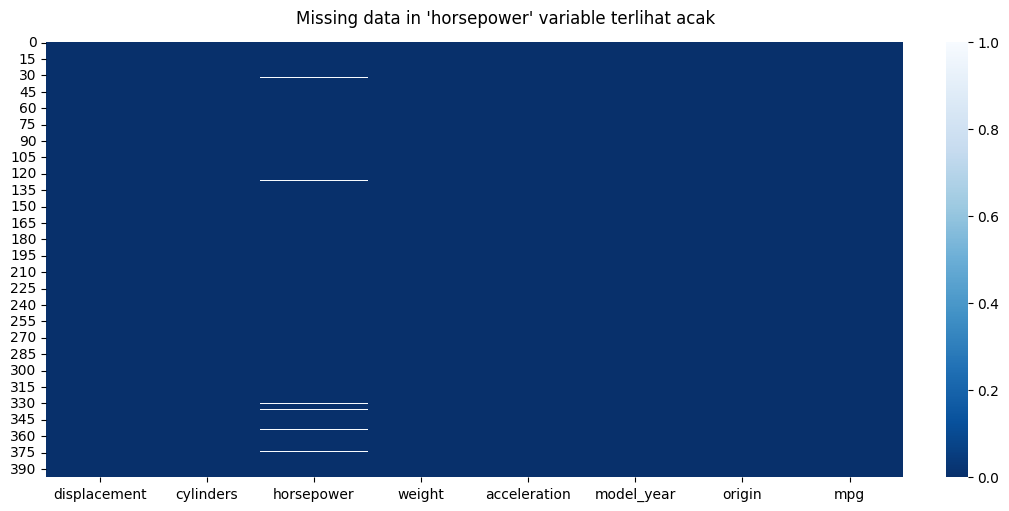

In [5]:
# create & setup plot figure
width, height = 10, 5
plt.figure(
    figsize=(width, height),
    layout="constrained"
)
plt.suptitle(t="Missing data in 'horsepower' variable terlihat acak")

# plot heatmap consisting of missing data
sns.heatmap(
    data=data.isna().sort_index(),
    cmap="Blues_r"
)
plt.show()

* Heatmap di atas menunjukkan:
    * Garis berwarna putih pada kolom `horsepower` yang merepresentasikan missing data pada kolom tersebut, dan
    * Sumbu `y` menunjukkan lokasi (indeks) missing data tersebut dalam data.
* Dari visualisasi ini, dapat diinterpretasikan bahwa:
    * Missing data terletak pada lokasi yang acak pada `horsepower`;
    * Missing data terpisah satu sama lain, tidak berdekatan, berhimpitan maupun membentuk pola tertentu.

In [6]:
# slice missing data in train set
data[data["horsepower"].isnull()]

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin,mpg
32,98.0,4,NaN,2046,19.0,71,1,25.0
126,200.0,6,NaN,2875,17.0,74,1,21.0
330,85.0,4,NaN,1835,17.3,80,2,40.9
336,140.0,4,NaN,2905,14.3,80,1,23.6
354,100.0,4,NaN,2320,15.8,81,2,34.5
374,151.0,4,NaN,3035,20.5,82,1,23.0


* DataFrame di atas menunjukkan:
    * Sampel dengan missing data pada `horsepower`,
    * Nilai pada variabel lain dalam data dengan missing data tersebut, dan
    * Indeks dari missing data dalam data.
* A priori, dapat disimpulkan bahwa:
    * Tidak ada indikasi bahwa missing data tersebut are dependent on any other variable.
    * Ambil contoh dari kolom `displacement`: missing data memiliki nilai `displacement` yang beragam.

In [7]:
# perform Little's MCAR test
mcar_test = MCARTest(method="little")
mcar_test_pvalue = mcar_test.little_mcar_test(X=data)

*Little's MCAR Test (1988) adalah:*
* *Statistical hypothesis test untuk Missing Completely At Random (MCAR).*
    * *Null hypothesis: data is MCAR*
    * *Alternative hypothesis: data is not MCAR*
* *Metode yang digunakan adalah chi-square test on the entire data; membandingkan kelompok data dengan missing value terhadap kelompok data tanpa missing value to determine if there is a significant relationship between the two groups.*

In [8]:
def mcar_test_evaluation(mcar_test_decision):
    """Evaluates the results of Little's MCAR test.
    
    Args:
        mcar_test_decision (str): The decision made based on the MCAR test, 
        indicating whether the null hypothesis is rejected or not.
    
    Returns:
        pd.DataFrame: A DataFrame summarizing the p-value and decision of the test, 
        with the p-value and decision as rows and their corresponding values.
    """
    mcar_test_summary = pd.DataFrame(
        data=[mcar_test_pvalue,
              mcar_test_decision],
        index=["p-value",
               "decision"],
        columns=["value"]
    )
    return mcar_test_summary

# evaluate MCAR test's p-value
significance_level = 0.05
if mcar_test_pvalue >= significance_level:
    display(mcar_test_evaluation(mcar_test_decision="Accept H0"))
else:
    display(mcar_test_evaluation(mcar_test_decision="Accept Ha"))

,value
p-value,0.313475
decision,Accept H0


* Hasil observasi secara visual, tabular, serta uji statistik di atas memberikan inferensi bahwa missing data tersebut adalah MCAR.
* When data is MCAR, there is absolutely no relationship between the data missing and any other values, observed or missing, within the data.
    * In other words, those missing data points are a random subset of the data.
    * There is nothing systematic going on that makes some data more likely to be missing than other.
* If values for observations are missing completely at random, then disregarding those cases would not bias the inferences made.

In [9]:
# discard missing data from the dataset
dropper = DropMissingData()

data = pd.DataFrame(
    data=dropper.fit_transform(X=data),
    columns=dropper.get_feature_names_out()
)

* *Transformation yang digunakan pada `data_train` [juga diterapkan pada subsequent datasets](https://scikit-learn.org/stable/common_pitfalls.html#inconsistent-preprocessing), whether it's `data_test` or data in a production system.*
* *Discarding the missing data uses `DropMissingData()` transformer, karena transformer ini compatible dengan Scikit-learn pipeline yang akan digunakan pada bagian-bagian berikutnya.*

#### Invalid Data Type

In [10]:
# encode selected variables in dataset to Pandas' "categorical" data type
matcher = MatchCategories(
    variables="origin",
    ignore_format=True
)

data = pd.DataFrame(
    data=matcher.fit_transform(X=data),
    columns=matcher.get_feature_names_out()
)

Variabel `origin` dengan tipe data nominal juga merupakan bagian dari tipe data kategorikal, sehingga
* `MatchCategories()` transformer dapat digunakan untuk mengubah tipe data variabel tersebut.
* Hasil transformasi tipe data ini serta penghapusan missing data sebelumnya akan disajikan pada bagian berikut.

#### Inspection Summary

In [11]:
# perform final inspection on cleaned train set
pd.DataFrame(data={
    "dtype": data.dtypes,
    "missing": data.isna().sum()
})

,dtype,missing
displacement,float64,0
cylinders,int64,0
horsepower,float64,0
weight,int64,0
acceleration,float64,0
model_year,int64,0
origin,category,0
mpg,float64,0


* Variabel `origin` yang sebelumnya bertipe integer berhasil dikonversi ke tipe data kategorikal yang sesuai, dan
* Missing data succesfully dropped from the `data_train`.

---

## Section 2 | Exploratory Data Analysis

[Exploratory data analysis](https://en.wikipedia.org/wiki/Exploratory_data_analysis) (EDA) is an approach of analyzing data sets to summarize their main characteristics, often using statistical methods and data visualization graphics. EDA encompasses [IDA](#section-1--initial-data-analysis) yang telah dilakukan sebelumnya.

In [ ]:
# import required libraries for this section
import numpy as np
from sklearn.model_selection import train_test_split
from scipy.stats import normaltest
from dython.nominal import associations

### Train-Test Split

In [13]:
# set random state seed
seed = 42
random_state = np.random.RandomState(seed=seed)

*Some scikit-learn `sklearn` objects are [inherently random](https://scikit-learn.org/stable/common_pitfalls.html#controlling-randomness). The randomness of these objects is controlled via their `random_state` parameter.*
* *In order to obtain reproducible (i.e. constant) results across multiple executions of this project, the recommended way is by passing a random number generator `RandomState` instance to any of those objects that accept a `random_state` parameter.*
* *Random seed yang digunakan secara arbitrary dalam project ini adalah [42](https://en.wikipedia.org/wiki/42_(number)).*

In [14]:
# split dataset to random train and test subsets
data_train, data_test = train_test_split(
    data,
    random_state=random_state
)

data_train, data_test = pd.DataFrame(data=data_train), pd.DataFrame(data=data_test)

In [15]:
def inspect_dimensionality(dataset, train, test):
    """Performs dimensionality analysis of the dataset and its train-test subsets.

    Args:
        dataset (pd.DataFrame): The original dataset.
        train (pd.DataFrame): The training subset of the dataset.
        test (pd.DataFrame): The testing subset of the dataset.
        
    Returns:
        pd.DataFrame: A DataFrame summarizing the number of rows, row ratio, 
        and number of columns for the dataset and its subsets.
    """
    dimensionality_summary = pd.DataFrame(
        data=[(dataset.shape[0], (dataset.shape[0] / dataset.shape[0]), dataset.shape[1]),
              (train.shape[0], (train.shape[0] / dataset.shape[0]), train.shape[1]),
              (test.shape[0], (test.shape[0] / dataset.shape[0]), test.shape[1])],
        index=["dataset", "train", "test"],
        columns=["row (n)", "row ratio", "column"]
    )
    return dimensionality_summary

In [16]:
inspect_dimensionality(
    dataset=data,
    train=data_train,
    test=data_test
)

,row (n),row ratio,column
dataset,392,1.00,8
train,294,0.75,8
test,98,0.25,8


Tabel di atas mendeskripsikan dimensionality dari Auto MPG dataset setelah splitting dilakukan menjadi train dan test subsets:
* Keseluruhan dataset terdiri dari `392` baris dan `8` kolom.
* `train_test_split` membagi `data` tersebut menjadi sepasang `data_train` dan `data_test`.
    * Jumlah baris dalam dataset dibagi menjadi `~0.75/75%` untuk data train dan `~0.25/25%` untuk data test, sesuai default parameter.
    * Splitting ini hanya membagi tiap baris/observasi, sehingga jumlah kolom/variabel tidak berubah.
* The following section akan berfokus pada analisis untuk `data_train`.
    * Bagian data ini berperan untuk melatih parameter dalam pemodelan, sedangkan
    * `data_test` digunakan untuk mengevaluasi performa model tersebut pada unseen data, ensuring it generalizes well to new examples.

### Univariate EDA

Univariate analysis is the simplest form of data analysis, focusing on describing and summarizing a single variable at a time. It analyzes the distribution, central tendency (mean, median, mode), and dispersion (range, variance) to identify patterns, outliers, and data characteristics, rather than examining relationships between variables.

#### Statistical Analysis

In [17]:
# subset numerical variables from train set
numerical_train = data_train.select_dtypes(include="number")

# generate descriptive statistics for numerical variables
numerical_train\
    .describe()\
        .round(decimals=2)

,displacement,cylinders,horsepower,weight,acceleration,model_year,mpg
count,294.00,294.00,294.00,294.00,294.00,294.00,294.00
mean,195.48,5.47,104.47,2971.83,15.51,76.14,23.69
std,104.66,1.71,38.60,841.77,2.86,3.65,8.01
min,70.00,3.00,46.00,1613.00,8.00,70.00,9.00
25%,105.00,4.00,75.00,2227.00,13.50,73.00,17.50
50%,151.00,4.00,92.50,2781.50,15.40,76.00,23.00
75%,302.00,8.00,129.75,3625.75,17.30,79.00,30.00
max,455.00,8.00,230.00,5140.00,24.80,82.00,46.60


* The exact numerical statistics for `numerical_variables` are provided above in tabular format:
    * `count` refers to the number of non-null values for each columns (similar with `Row/Instance` values in [Section 1: Data Inspection](#data-inspection)),
    * `mean` measures the [average](https://en.wikipedia.org/wiki/Arithmetic_mean) of the values over each columns,
    * `std` represents the [standard deviation](https://en.wikipedia.org/wiki/Standard_deviation) for each variables,
    * `min` and `max` are the minimum and maximum of the values in each columns, respectively, and
    * `25%`, `50%` and `75%` are the corresponding [percentiles](https://en.wikipedia.org/wiki/Percentile) (`50%` percentile juga bisa disebut dengan [median](https://en.wikipedia.org/wiki/Median))
* Terdeteksi adanya perbedaan rentang nilai atau [**order of magnitude**](https://en.wikipedia.org/wiki/Order_of_magnitude) antar variabel numerikal:
    * Mulai dari rentang satuan `8.00` pada variabel `acceleration` hingga ribuan `5140.00` pada variabel `weight`.
    * Keragaman nilai ini may pose several problems in machine learning:
        * In Linear Regression models, the scale of variables used to estimate the output matters. Linear models are of the type $y = wx + b$, where the regression coefficient $w$ represents the expected change in $y$ for a one unit change in $x$ (the predictor).
        * Thus, the magnitude of $w$ is partly determined by the magnitude of the units being used for $x$. If $x$ is a mass variable, just changing the scale from pounds to grams will cause a change in the magnitude of the coefficient.
    * *Dapat dilihat juga bahwa secara keseluruhan, nilai numerik dari Auto MPG train set berada pada rentang nilai positif (> 0).*

In [18]:
# perform statistical tests numerical variables
test_results = list()

for variable in numerical_train:
    skewness = numerical_train[variable].skew()
    kurtosis = numerical_train[variable].kurt()
    k2_statistic, pvalue = normaltest(a=numerical_train[variable])
    decision = 'Reject H0' if pvalue <= 0.05 else 'Accept H0'
    test_results.append({
        'skewness': skewness,
        'kurtosis': kurtosis,
        'k2_statistic': k2_statistic,
        'pvalue': pvalue,
        'decision': decision
    })

# tests summary in DataFrame format
pd.DataFrame(
    data=test_results,
    index=numerical_train.columns
)

,skewness,kurtosis,k2_statistic,pvalue,decision
displacement,0.656112,-0.860827,47.765773,4.244183e-11,Reject H0
cylinders,0.514356,-1.404709,1334.141918,1.971349e-290,Reject H0
horsepower,1.039396,0.553633,42.080370,7.283897e-10,Reject H0
weight,0.504710,-0.799812,33.872564,4.412311e-08,Reject H0
acceleration,0.301467,0.207494,5.104956,7.788841e-02,Accept H0
model_year,-0.063191,-1.149152,117.242192,3.476815e-26,Reject H0
mpg,0.416127,-0.623174,17.915961,1.287059e-04,Reject H0


* Uji statistik yang digunakan berfokus pada normalitas distribusi dari tiap kolom numerik dalam dataset.
    * Pertama-tama, disertakan hasil pengukuran unbiased, normalized [skewness](https://en.wikipedia.org/wiki/Skewness) and excess [kurtosis](https://en.wikipedia.org/wiki/Kurtosis) dari tiap kolom.
        * *Positive value of skewness indicates variable with positive distribution or right-skewed, and so otherwise; while*
        * *Excess kurtosis value above 3 indicating variable with more extreme outliers than normal distribution (leptokurtic), and otherwise for below 3 (mesokurtic).*
    * Dan dari nilai tersebut, hanya ada satu kolom `acceleration` yang memiliki hasil pengukuran seperti distribusi normal: skewness dan excess kurtosis ≈ 0.
    * Sehingga dapat disimpulkan bahwa variables dalam dataset selain `acceleration` bersifat non-normal/non-parametrik.
* Selaras dengan nilai skewness dan kurtosis yang telah dipaparkan, uji statistik berikutnya menggunakan [D'Agostino-Pearson](https://en.wikipedia.org/wiki/D%27Agostino%27s_K-squared_test) `normaltest` for gauging the compatibility of given data with the null hypothesis that the data is a realization of independent, identically distributed Gaussian random variables.
    * This particular test uses skewness and kurtosis to measure how much data deviate from normality (in both tails and asymmetry).
    * Kedua nilai tersebut diubah menjadi approximately standard normal samples $Z_1\, \&\, Z_2$, untuk kemudian dikombinasikan menjadi chi-squared menggunakan persamaan $K^2=Z_1^2+Z_2^2$.
    * `normaltest` menghasilkan nilai test `statistic` yang mengukur seberapa jauh estimasi distribusi variabel dengan parameter dalam null hypothesis, dan `pvalue` untuk menginterpretasikan tes statistik tersebut.
* Dengan $\text{significance level}=0.05$, dan `pvalue` dari tiap uji statistik di atas terkecuali untuk variabel `acceleration` berada di bawah signifikansi:
    * Maka dapat diambil keputusan untuk reject null hypothesis pada uji statistik tersebut, dan
    * Assume bahwa tiap variabel selain `acceleration` *tidak berasal dari populasi dengan distribusi normal*.

#### Data Visualization

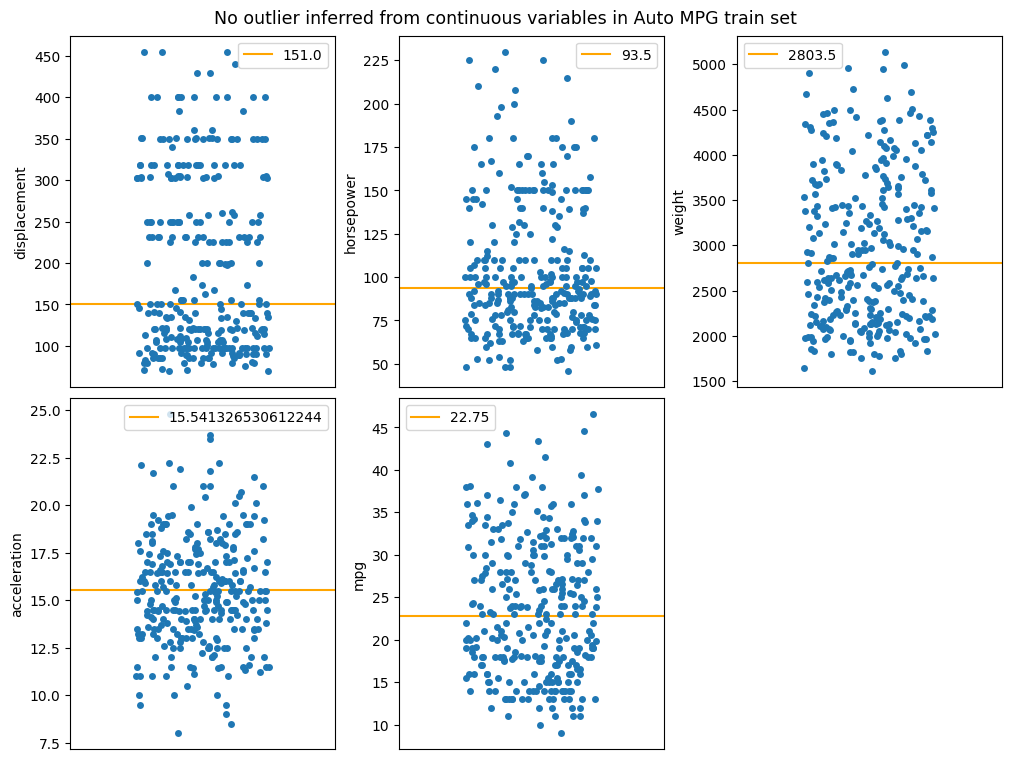

In [19]:
# create & setup plot figure
width, height = 10, 7.5
plt.figure(
    figsize=(width, height),
    layout="constrained"
)
suptitle_size = 12.5
plt.suptitle(
    t="No outlier inferred from continuous variables in Auto MPG train set",
    size=suptitle_size
)

# subset variables with continuous data type from numerical variables
discrete_columns = ["cylinders", "model_year"]
continuous_train = numerical_train.drop(columns=discrete_columns)

# plot visualization for continuous variables
nrows, ncols = 2, 3
for count, column in enumerate(iterable=continuous_train):
    plt.subplot(nrows, ncols, count + 1)
    
    def plot_strip():
        kwargs = dict(data=continuous_train, y=column, jitter=0.25)
        axes = sns.stripplot(**kwargs)
        axes.set_xticks(ticks=list())

        return axes

    if column != "acceleration":
        axes = plot_strip()

        median = data[column].median()
        median_line = plt.axhline(y=median, color="orange")
        axes.legend(handles=[median_line], labels=[median])
    
    else:
        axes = plot_strip()

        mean = data[column].mean()
        mean_line = plt.axhline(y=mean, color="orange")
        axes.legend(handles=[mean_line], labels=[mean])

[Strip plot](https://seaborn.pydata.org/tutorial/categorical.html#categorical-tutorial) digunakan untuk menunjukkan data points berdasarkan variabel numerik dalam Auto MPG dataset.
* Karena jumlah observasi dalam dataset dalam rentang ratusan dan relatif banyak, maka `jitter` with a certain value diterapkan untuk memvisualkan data points tersebut secara non-overlapping semaksimal mungkin.
* Beberapa insight dapat ditarik dari visualisasi sederhana ini seperti persebaran data, skewness, distribution gaps, hingga modality. Namun fokus analisa kali ini untuk mendeteksi keberadaan [outlier](https://en.wikipedia.org/wiki/Outlier) pada tiap variabel.
    * Ambil contoh variabel `displacement`, data points dengan nilai `~450` berada cukup jauh dari midpointnya (orange median line) of `151`.
    * Meskipun demikian, outside values ini tidak jauh berbeda dengan data points di sekitarnya, dan bukanlah sebuah error sebagaimana yang disampaikan pada [Initial Data Inspection](#initial-data-inspection), sehingga ia dapat didefinisikan sebagai *non-outlier*.

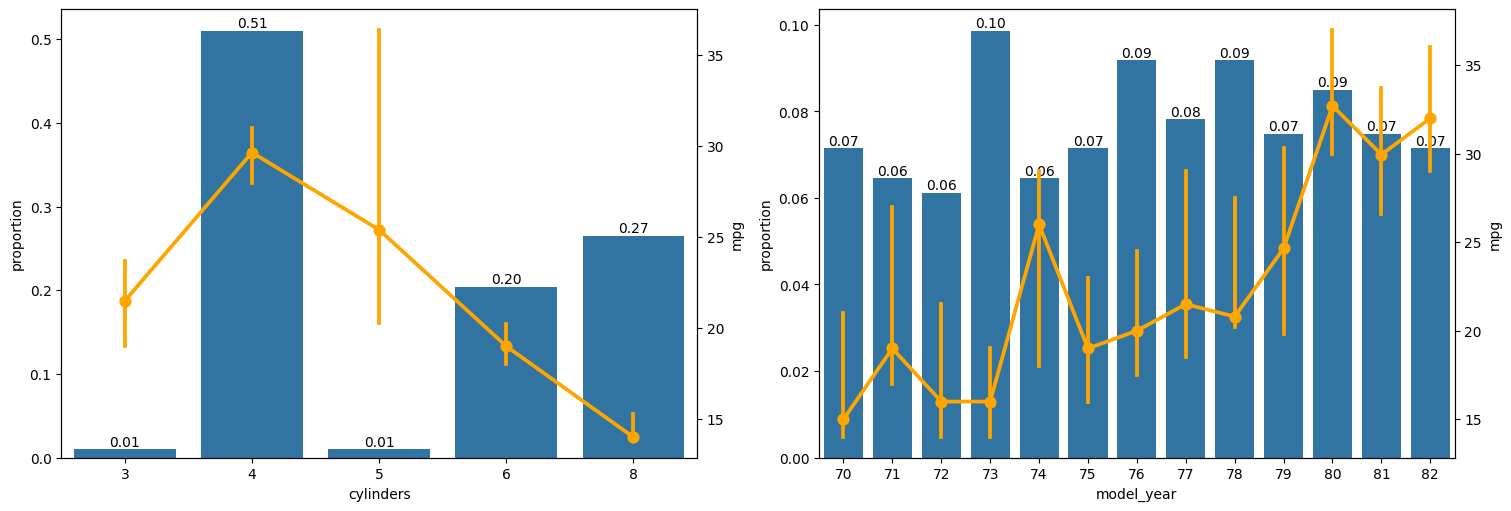

In [20]:
# create & setup plot figure
width, height = 15, 5
plt.figure(
    figsize=(width, height),
    layout="constrained"
)
# suptitle_size = 12.5
# plt.suptitle(
#     t="Differing magnitude but no outlier inferred from continuous variables",
#     size=suptitle_size
# )

continuous_columns = pd.DataFrame(data=continuous_train).drop(columns="mpg")
discrete_train = numerical_train.drop(columns=continuous_columns)
nrows, ncols = 1, 2
for count, column in enumerate(iterable=discrete_train):
    if column != "mpg":
        plt.subplot(nrows, ncols, count + 1)
        kwargs = dict(data=discrete_train, x=column)
        axes = sns.countplot(
            **kwargs,
            stat="proportion"
        )
        axes.bar_label(
            container=axes.containers[0],
            fmt='%.2f'
        )

        axes_twinx = axes.twinx()
        sns.pointplot(
            **kwargs,
            y="mpg",
            estimator="median",
            errorbar="ci",
            seed=random_state,
            color="orange",
            ax=axes_twinx,
        )

        # plt.show()

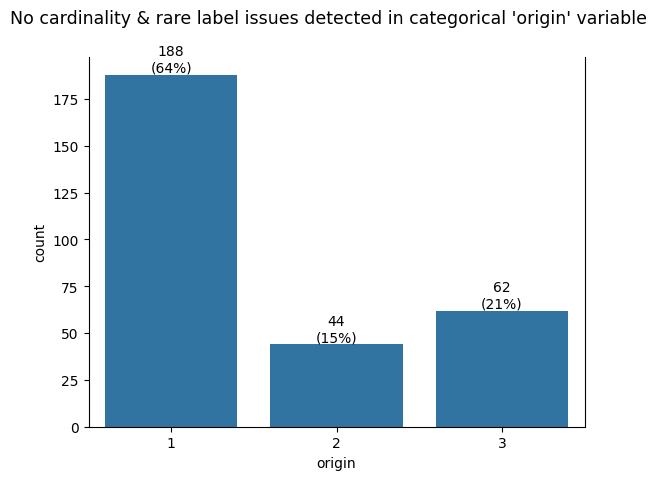

In [21]:
# setup plot title
suptitle_size = 12.5
plt.suptitle(
    t="No cardinality & rare label issues detected in categorical 'origin' variable",
    size=suptitle_size
)

# plot visualization for categorical variables
barplot_data = pd.concat(
    objs=[data_train["origin"].value_counts().sort_index(),
          data_train["origin"].value_counts(normalize=True).mul(other=100)],
    axis=1
)

axes = sns.barplot(
    data=barplot_data, 
    x=barplot_data.index,
    y="count"
)

labels = [f"{round(number=value.get_height())}\n({round(number=barplot_data.iloc[index, 1])}%)"
            for index, value in enumerate(axes.containers[0])]

axes.bar_label(
    container=axes.containers[0], 
    labels=labels
)
axes.spines.top.set_visible(b=False)

[Bar chart](https://en.wikipedia.org/wiki/Bar_chart) is a chart that presents categorical data with rectangular bars with heights or lengths proportional to the values that they represent.
* The graph shows comparisons among discrete categories.
    * For these particular graphs, one axis of the chart shows the specific categories being compared, and the other axis represents a measured value.
    * Categorical variables are those which values are selected from a group of categories —also called labels.
    * Tiap grafik dalam plot di atas merepresentasikan labels yang berada dalam variabel tertentu dan occurences (count) dari label tersebut.
    * Ambil contoh pada variabel `origin`, labels dengan occurences tertinggi adalah `1` sejumlah `183` observations atau `62%` dari keseluruhan data.
* Berdasarkan visualisasi ini, tidak terdeteksi any particular issues with the only categorical feature in Auto MPG dataset
    * The variable `origin` contains only 3 labels; a definite small number of cardinality
    * Meskipun label `1` dari variabel ini mendominasi dengan `64%` frekuensi, tetapi label `2` dan `3` lainnya cukup sering ditemukan dengan masing-masing mencakup `15%` dan `21%` dari keseluruhan data.

### Multivariate EDA

[Multivariate analysis](https://en.wikipedia.org/wiki/Multivariate_statistics) encompasses the simultaneous observation and analysis of more than one variables, in order to understand the relationships between them and their relevance to the problem being studied. It may also determine to what extent it becomes easier to know and predict a value for one variable (possibly a dependent variable) if the value of the other variable (possibly the independent variable) is known.

#### Linear Regression

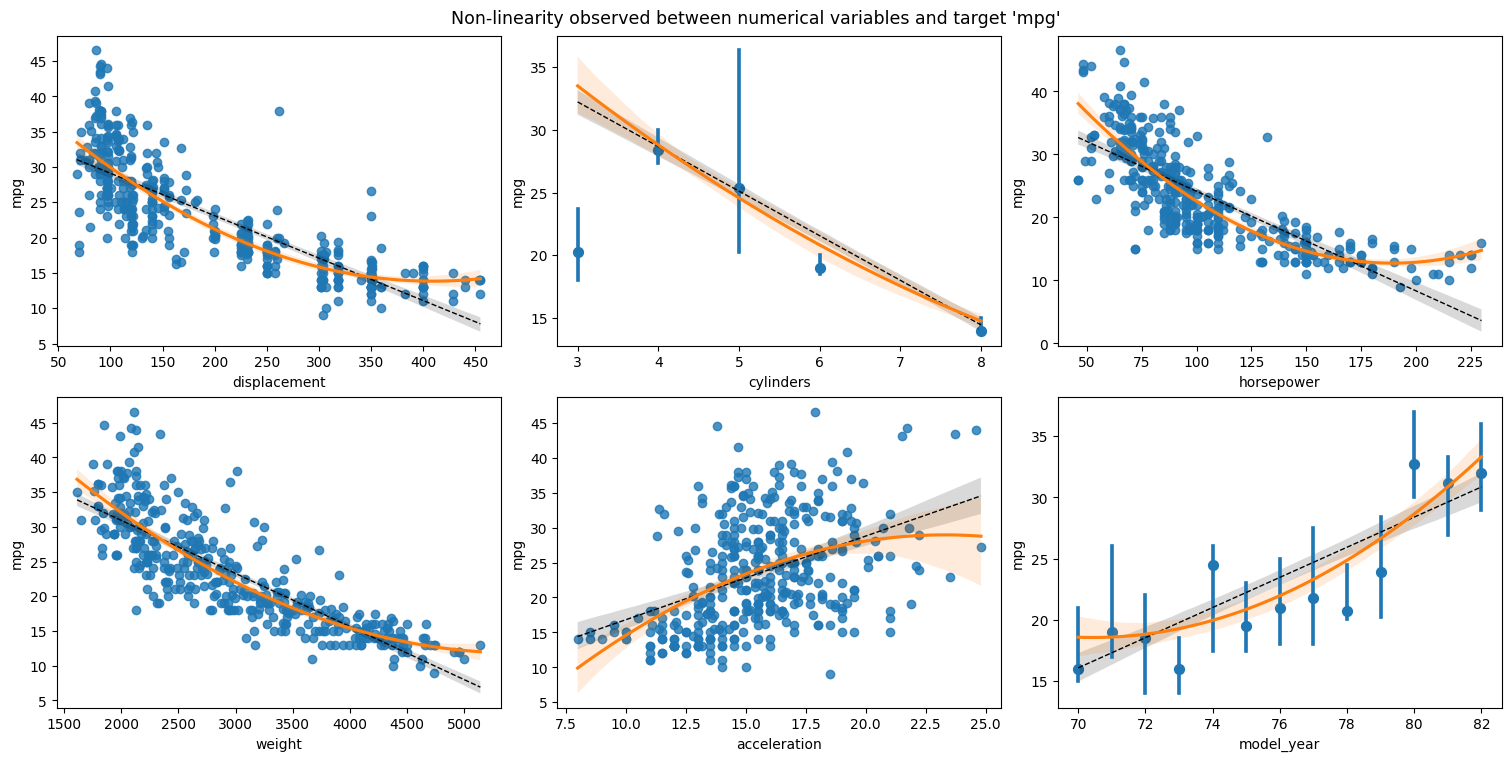

In [22]:
# create & setup plot figure
width, height = 15, 7.5
plt.figure(
    figsize=(width, height),
    layout="constrained"
)
suptitle_size = 12.5
plt.suptitle(
    t="Non-linearity observed between numerical variables and target 'mpg'",
    size=suptitle_size
)

# plot visualization for continuous variables against target variable
nrows, ncols = 2, 3
for count, column in enumerate(iterable=numerical_train):
    if column != "mpg":
        plt.subplot(nrows, ncols, count + 1)
        kwargs = dict(data=data, x=column, y="mpg")

        def viz_regplot(x_estimator=None):
            sns.regplot(
                **kwargs,
                x_estimator=x_estimator,
                order=1,
                line_kws={
                    "color": "black",
                    "linestyle": "dashed",
                    "linewidth": 1
                }
            )

            sns.regplot(
                **kwargs,
                scatter=False,
                order=2
            )
        
        if column not in discrete_columns:
            viz_regplot()
        else:
            viz_regplot(x_estimator=np.median)

[Regression plot](https://seaborn.pydata.org/tutorial/regression.html#regression-tutorial) as shown above has two main functions:
1. Depicts the joint distribution of two variables using a scattered cloud of points, where each point represents an observation in the dataset.
    * There is a clear negative, **non-linear relationship** between `displacement, horsepower, & weight` and `mpg`.
    * Seiring bertambahnya those variables, fuel efficiency decreases.
    * Pengurangan ini is not strictly linear: sharper at lower variable values and gradual at higher values.
    * Hal ini mengindikasikan bahwa simple linear models may not capture the true relationship between these independent variables against the target.
2. Fit the regression model with $y$ as a function of $x$, and plot the resulting regression line with 95% confidence interval for that regression.
    * black dashed line merepresentasikan linear fit `order=1` dari pasangan continuous variable `x` dan target variable `y`, sedangkan
    * orange line merupakan non-linear (polynomial) fit `order=2` dari pasangan variabel tersebut.
    * untuk ketiga pasangan variabel yang sama, linear fit deviates at the extremes and misses the pattern, while
    * the polynomial fit is appropriate, since curvature and convex shape is visible from the scatter plot
* *Hubungan yang berlawanan didapatkan pada pasangan variabel `acceleration - mpg`: very scattered data points and no clear pattern from the distribution.*

#### Strength-of-Association

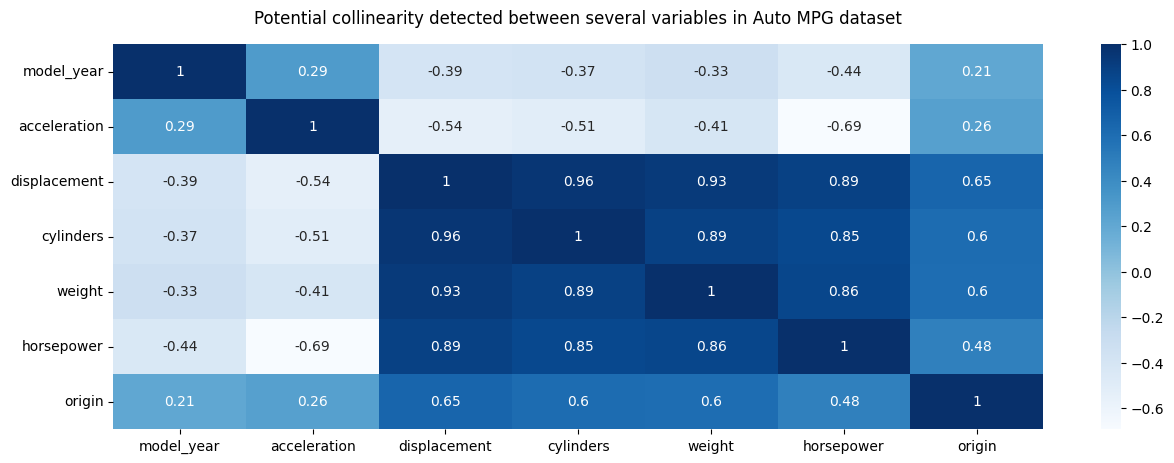

In [23]:
# calculate correlations between variables in train set
associations_dicts = associations(
    dataset=pd.DataFrame(data=data_train).drop(columns=["mpg"]), 
    num_num_assoc="pearson",
    nom_nom_assoc="correlation_ratio",
    plot=False,
    clustering=True
)

# access correlation matrix
for key, value in associations_dicts.items():
    if key == "corr":
        corr_matrix = value

        # create & setup plot figure
        width, height = 15, 5
        plt.figure(figsize=(width, height))
        plt.title(
            label="Potential collinearity detected between several variables in Auto MPG dataset",
            pad=15
        )
        
        # plot heatmap for correlation matrix
        sns.heatmap(
            data=corr_matrix,
            cmap="Blues",
            annot=True
        )

Visualisasi heatmap di atas merepresentasikan [korelasi](https://en.wikipedia.org/wiki/Correlation) dari tiap pasangan variabel dalam Auto MPG dataset.
* Korelasi antar variabel numerik menggunakan metode [Spearman's rank correlation](https://en.wikipedia.org/wiki/Spearman%27s_rank_correlation_coefficient) dengan mempertimbangkan distribusi non-parametrik pada variabel tersebut, sesuai temuan pada [Section 2: Visual Analysis](#visual-analysis).
* Dan untuk pasangan variabel kategorikal-numerikal menerapkan [Correlation ratio](https://julius.ai/articles/harnessing-the-power-of-the-correlation-ratio-in-data-analysis), yang appropriate untuk categorical independent variable `origin` with the rest of numerical independent variables.

The computed associations are also sorted into groups by similar correlations from the `clustering` parameter, dan dengan fokus analisis pada [multicollinearity](https://en.wikipedia.org/wiki/Multicollinearity) between predictors, dapat diobservasi beberapa temuan berikut:
* Kluster pertama antara pasangan variabel `model_year, & acceleration` from both x-axis & y-axis —additionally with the `origin` variable— merupakan variables dengan relatively moderate, positive strength of association; koefisien korelasinya berkisar antara `0.21 - 0.28`.
* Kluster kedua dari variable `displacement, cylinders, weight, & horsepower` dengan `model_year & acceleration` bernilai sebaliknya, yakni negatively moderate strength antara `-0.31 - -0.68`.
* Kluster ketiga antara pasangan variabel `displacement, cylinders, weight, & horsepower` have a high positive strength of correlation; ranges from `0.81 - 0.94`. Kondisi ini juga disebut dengan **imperfect multicollinearity**.
    * Imperfect collinearity makes precise estimation of variables difficult. In other words, highly correlated variables lead to poor estimates and large standard errors.
    * The problem with trying to identify how much each of the two variables matters is that they are confounded with each other: observations are explained equally well by either variable, so it is impossible to know which one of them causes the observed correlations.

### Analysis Summary

| Anomaly | Description |
| --- | --- |
| Variable Magnitude | Terdeteksi adanya perbedaan magnitude antar numerical variables |
| Linearity | Tampak adanya non-linear relationship antara independent variable `displacement, horsepower, & weight` dengan target variable `mpg` |
| Multicollinearity | Kondisi imperfect multicollinearity terjadi antara pasangan variabel `displacement, cylinders, weight, & horsepower` |

---

## Section 3 | Predictive Modeling

In [ ]:
# import required libraries for this section
from sklearn.preprocessing import PowerTransformer, PolynomialFeatures, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer, make_column_selector, TransformedTargetRegressor
from sklearn.linear_model import ElasticNet
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.metrics import mean_squared_error, make_scorer
from sklearn.model_selection import KFold, GridSearchCV, cross_val_score

### Feature Engineering

Feature engineering is a preprocessing step in supervised machine learning and statistical modeling which transforms raw data into a more effective set of inputs.
* Each input comprises several attributes, known as features.
* By providing models with relevant information, feature engineering significantly enhances their predictive accuracy and decision-making capability.

#### Feature-Target Split

In [25]:
def feature_target_split(dataset, random_state):
    """Splits the dataset into features and target variables for training and testing.

    Args:
        dataset (pd.DataFrame): The input dataset containing features and target variable.
        random_state (int): The random state seed for reproducibility.
        
    Returns:
        pd.DataFrame, pd.DataFrame, pd.Series, pd.Series: The training and testing subsets for features and target variable.
    """
    X, y = dataset.drop(columns="mpg"), dataset["mpg"]
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        random_state=random_state
    )

    return X_train, X_test, y_train, y_test

In machine learning:
* Features are the input variables (independent variables) used to make predictions, while
* The target is the variable to be predicted or understood (dependent variable).
* Together, they form the basis for supervised learning, where features map to a target value. Features are selected for relevance, and the target is the goal.

In [26]:
# split features and target to random train and test subsets
X_train, X_test, y_train, y_test = feature_target_split(
    dataset=data,
    random_state=random_state
)

# perform dimensionality analysis of train-test subsets
inspect_dimensionality(
    dataset=data,
    train=X_train,
    test=X_test
)

,row (n),row ratio,column
dataset,392,1.00,8
train,294,0.75,7
test,98,0.25,7


Proses splitting di atas kurang lebih serupa dengan yang telah dilakukan pada [Section 2: Train-Test Split](#train-test-split), dengan beberapa perbedaan:
* `feature_target_split` membagi `data` menjadi 2 pasang `X_train - X_test` dan `y_train - y_test`.
* Proporsi pembagian dataset ini tetap sama, namun karena target variabel `mpg` turut dipisahkan menjadi `y_train & y_test`, jumlah kolom pada `train & test` —dengan kata lain, `X_train & X_test`— berkurang 1 variabel.

#### Power Transformer

Feature scaling through [standardization](https://scikit-learn.org/stable/auto_examples/preprocessing/plot_scaling_importance.html#sphx-glr-auto-examples-preprocessing-plot-scaling-importance-py) —also called Z-score normalization— is an important preprocessing step for many machine learning algorithms.
* Standardization of datasets is a [common requirement](https://scikit-learn.org/stable/modules/preprocessing.html#standardization-or-mean-removal-and-variance-scaling) for many machine learning estimators implemented in scikit-learn.
* They might behave badly if the individual features do not more or less look like standard normally distributed data: Gaussian with zero mean and unit variance, sebagaimana ditunjukkan berikut ini.
* Dan considering temuan pada [Section 2: Exploratory Data Analysis](#exploratory-data-analysis) yang menyatakan bahwa variabel numerik dalam Auto MPG dataset berdistribusi non-normal, maka transformasi data menuju Gaussian menggunakan [PowerTransformer](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PowerTransformer.html) diperlukan untuk mempersiapkan data sebelum tahap pemodelan.

In [27]:
# transform numerical features in train set
transformer = PowerTransformer(method="box-cox")

holdout_numerical = pd.DataFrame(
    data=transformer.fit_transform(X=numerical_train),
    columns=transformer.get_feature_names_out()
)

# generate descriptive statistics for transformed numerical features
holdout_numerical.describe()

,displacement,cylinders,horsepower,weight,acceleration,model_year,mpg
count,2.940000e+02,2.940000e+02,2.940000e+02,2.940000e+02,2.940000e+02,2.940000e+02,2.940000e+02
mean,2.090542e-15,1.238616e-15,-7.504201e-15,-6.764053e-15,-2.477232e-16,-1.996891e-15,-5.196146e-16
std,1.001705e+00,1.001705e+00,1.001705e+00,1.001705e+00,1.001705e+00,1.001705e+00,1.001705e+00
min,-1.795838e+00,-2.404920e+00,-2.563668e+00,-2.178085e+00,-3.019346e+00,-1.659898e+00,-2.414624e+00
25%,-8.919804e-01,-8.839809e-01,-7.632968e-01,-8.873991e-01,-6.803469e-01,-8.645563e-01,-7.265150e-01
50%,-1.554096e-01,-8.839809e-01,-1.020992e-01,-5.998399e-02,9.343157e-03,-5.073732e-02,4.464751e-02
75%,1.079225e+00,1.328424e+00,8.442181e-01,8.647414e-01,6.569869e-01,7.812333e-01,8.417008e-01
max,1.715911e+00,1.328424e+00,2.156493e+00,1.987085e+00,2.913671e+00,1.631048e+00,2.273473e+00


* *Metode Box-Cox digunakan sesuai temuan pada [Section 2: Visual Analysis](#visual-analysis); karena data [bernilai positif](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PowerTransformer.html), dan [performs better](https://scikit-learn.org/stable/auto_examples/preprocessing/plot_map_data_to_normal.html#sphx-glr-auto-examples-preprocessing-plot-map-data-to-normal-py) than Yeo-Johnson*.
* Setelah melalui standarisasi, tiap variabel numerik dalam data memiliki `mean` yang mendekati nol. Serta `std` dalam satuan unit yang sama.
* Proses ini juga meratakan order of the magnitude, sehingga nilai tiap variabel are within about a factor of 10 from each other.

#### Polynomial Features

Sebagaimana yang telah didemonstrasikan pada [Section 2: Linear Regression](#linear-regression), it is useful to add complexity to the model by considering nonlinear features of the data.
* A simple and common method to use is [PolynomialFeatures](https://scikit-learn.org/stable/modules/preprocessing.html#generating-polynomial-features), which can get features' high-order terms.
* This technique enables linear models to map complex patterns —such as curves— and improve model accuracy when data shows a non-linear relationship.

In [28]:
# subset features from transformed numerical variables in train set
holdout_numerical_features = holdout_numerical.drop(columns="mpg")

# generate polynomial features on continuous variables
generator = PolynomialFeatures(degree=2, include_bias=False)
holdout_polynomial = pd.DataFrame(
    data=generator.fit_transform(X=holdout_numerical_features),
    columns=generator.get_feature_names_out()
)

# standardize polynomial features
scaler = StandardScaler()
holdout_polynomial = pd.DataFrame(
    data=scaler.fit_transform(X=holdout_polynomial),
    columns=scaler.get_feature_names_out()
)

# generate descriptive statistics for polynomial features
holdout_polynomial\
    .describe()\
        .transpose()

,count,mean,std,min,25%,50%,75%,max
displacement,294.0,3.021015e-17,1.001705,-1.795838,-0.891980,-0.155410,1.079225,1.715911
cylinders,294.0,0.000000e+00,1.001705,-2.404920,-0.883981,-0.883981,1.328424,1.328424
horsepower,294.0,4.833624e-17,1.001705,-2.563668,-0.763297,-0.102099,0.844218,2.156493
weight,294.0,-5.135726e-17,1.001705,-2.178085,-0.887399,-0.059984,0.864741,1.987085
acceleration,294.0,0.000000e+00,1.001705,-3.019346,-0.680347,0.009343,0.656987,2.913671
model_year,294.0,-6.042030e-18,1.001705,-1.659898,-0.864556,-0.050737,0.781233,1.631048
displacement^2,294.0,-2.718914e-17,1.001705,-1.291623,-0.832013,0.019717,0.646676,2.874118
displacement cylinders,294.0,2.054290e-16,1.001705,-1.596000,-0.828637,-0.029494,0.753060,5.033307
displacement horsepower,294.0,9.667248e-17,1.001705,-1.646275,-0.837957,-0.228798,0.584451,2.949988
displacement weight,294.0,-3.021015e-17,1.001705,-1.536846,-0.887805,-0.188517,0.722438,3.458070


* Polynomial features are generated on numerical features —including the discrete `cylinders & model_year` variables,
    * Karena the values are ordered (ex. year `70 - 82`) and there are meaningful distances between them (e.g. between `3 - 4` in `cylinders` is exactly 1 cylinder).
    * Contrasts with categorical features where squaring them are nonsensical (for example, $2^2$ value in `origin^2` doesn't mean anything).
* Generated features come from raising existing ones to a power and calculating their interaction terms, sebagaimana tampak pada DataFrame di atas.
    * Even if `PowerTransformer` applied before, these polynomial features can have different scales; seperti halnya permasalahan magnitude on the original data.
    * Oleh sebab itu, [`StandardScaler`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html) diterapkan to center the data around 0 and have variance/standard deviation in the same order.
    * *`include_bias` parameter set to `False` agar tidak terjadi duplikasi bias term (intercept) dengan [chosen downstream model](#modeling-pipeline).*
* `PolynomialFeatures` introduces the problem of **feature expansion**, where the number of features increases dramatically.
    * It is expected for several polynomial —especially for interaction terms such as `displacement cylinders`— to be highly correlated with the original feature.
    * Hence, creating new predictors that may further be deemed redundant than before.
    * Model complexity also increases with the number of independent variables, sehingga model yang appropriate akan implemented to handle these problems.

#### One-Hot Encoding

* Most machine learning models operate on mathematical computations —requiring numbers, not text. Sehingga encoding diperlukan untuk mengubah data dalam bentuk teks seperti categorical features menjadi numerik.
* Teknik encoding yang digunakan kali ini adalah yang paling umum diterapkan, yakni [one-hot encoding](https://scikit-learn.org/stable/modules/preprocessing.html#encoding-categorical-features). One-hot encoding transforms each categorical features with $n$ possible values into $n$ binary features, with one of them 1, and all others 0.

In [29]:
# encode categorical features in dataset, and
# inspect categorical features after encoding
categorical_train = pd.DataFrame(data=data_train).select_dtypes(include="category")
encoder = OneHotEncoder()

holdout_categorical = pd.DataFrame.sparse.from_spmatrix(
    data=encoder.fit_transform(X=categorical_train),
    columns=encoder.get_feature_names_out()
)
holdout_categorical.sample(n=5)

,origin_1,origin_2,origin_3
13,NaN,1.0,NaN
245,1.0,NaN,NaN
189,1.0,NaN,NaN
138,NaN,NaN,1.0
174,1.0,NaN,NaN


DataFrame di atas menampilkan hasil dari encoding pada 5 sample baris dari data train:
* Satu categorical variable `origin` yang memiliki 3 label diubah menjadi 3 numerical variable terpisah `origin_1, origin_2, & origin_3`.
* `OneHotEncoder` returns a [Compressed Sparse Row matrix](https://docs.scipy.org/doc/scipy/reference/generated/scipy.sparse.csr_matrix.html), a format for storing large, sparse matrices (mostly zero values) by storing only the non-zero elements.
    * For the "compressed" objects —where any data matching a specific value (in this case, 0)—, Pandas [interpret](https://pandas.pydata.org/docs/user_guide/sparse.html) them as `NaN` since the compressed values are not actually stored in the array, for memory-efficiency reasons.
    * Functionally, their behavior should be nearly identical to their dense matrix counterparts.
* Tiap variabel tersebut hanya memiliki 2 kemungkinan nilai di dalamnya yakni `NaN & 1`:
    * `NaN` adalah representasi dari Pandas to the omitted values of zero or 0.
    * `NaN` menandakan suatu observasi bukan bagian dari variabel tersebut dan sebaliknya untuk nilai `1`.

#### Preprocessing Summary

| Anomaly | Description |
| --- | --- |
| Variable Magnitude | `PowerTransformer` put the independent variables on a comparable scale/order of magnitude |
| Linearity | `PolynomialFeatures` introduce nonlinear relationship against the target variable into model yang akan digunakan |
| Multicollinearity | *To be analyzed further in [Section 3: Modeling Pipeline](#modeling-pipeline)* |
| Feature Expansion | *To be analyzed further in [Section 3: Modeling Pipeline](#modeling-pipeline)* |
| Encoding | `OneHotEncoder` applied as basic prerequisite for inputting categorical feature to machine learning algorithm |

### Modeling ETL

In [ ]:
def modeling_etl(id, random_state):
    """Modeling ETL process for data preparation and transformation.
    
    This function performs an Extract, Transform, Load (ETL) process on the dataset identified by the given UCI repository ID.
    It cleans the data by dropping missing values and matching categories based on specified variables.
    The cleaned data is then split into training and testing features and targets.
    
    Args:
        id (int): The UCI repository identifier for the dataset to be processed.
        random_state (int): The random state to ensure reproducibility of the data split.
    
    Returns:
        tuple: A tuple containing:
            - train_features (DataFrame): The features for the training set.
            - test_features (DataFrame): The features for the testing set.
            - train_target (Series): The target variable for the training set.
            - test_target (Series): The target variable for the testing set.
    """
    data = data_etl(id=id)

    dropper = DropMissingData()
    matcher = MatchCategories(
        variables="origin",
        ignore_format=True
    )
    pipeline = make_pipeline(dropper, matcher)
    data_cleaned = pipeline.fit_transform(X=data)
    
    train_features, test_features, train_target, test_target = feature_target_split(
        dataset=data_cleaned,
        random_state=random_state
    )

    return train_features, test_features, train_target, test_target

In [ ]:
# extract, transform, and load data for modeling
X_train, X_test, y_train, y_test = modeling_etl(
    id=auto_mpg_id,
    random_state=random_state
)

### Modeling Pipeline

In [32]:
def modeling_pipeline(alpha, l1_ratio, max_iter=5000):
    """Creates a modeling pipeline for regression tasks using ElasticNet with preprocessing steps for numerical and categorical features.
    
    Args:
        alpha (float): The constant that multiplies the L1 term in the ElasticNet penalty.
        l1_ratio (float): The ElasticNet mixing parameter, with 0 <= l1_ratio <= 1. 
                          For l1_ratio = 0 the penalty is an L2 penalty. 
                          For l1_ratio = 1 it is an L1 penalty.
        max_iter (int, optional): The maximum number of iterations for the ElasticNet solver. Defaults to 5000.
    
    Returns:
        Pipeline: A scikit-learn Pipeline object that includes preprocessing for numerical and categorical features,
                  and a transformed target regressor using ElasticNet.
    """
    transformer = PowerTransformer(method="box-cox")
    generator = PolynomialFeatures(degree=2, include_bias=False)
    scaler = StandardScaler()
    numerical_preprocessor = make_pipeline(
        transformer,
        generator,
        scaler
    )
    encoder = OneHotEncoder()
    categorical_preprocessor = make_pipeline(
        encoder
    )
    preprocessor = ColumnTransformer(
        [("NumericalPreprocessor", numerical_preprocessor, make_column_selector(dtype_include="number")),
         ("CategoricalPreprocessor", categorical_preprocessor, make_column_selector(dtype_include="category"))],
        verbose_feature_names_out=False
    )

    regressor = ElasticNet(
        alpha=alpha,
        l1_ratio=l1_ratio,
        fit_intercept=True,
        max_iter=max_iter,
        random_state=random_state
    )
    transformed_target_regressor = TransformedTargetRegressor(
        regressor=regressor,
        transformer=transformer
    )
    
    pipeline = Pipeline(
        [("preprocessor", preprocessor),
         ("transformedtargetregressor", transformed_target_regressor)]
    )

    return pipeline

Langkah-langkah yang diterapkan dalam pembuatan [pipeline](https://scikit-learn.org/stable/modules/compose.html#pipeline) untuk pemodelan adalah sebagai berikut:
1. Dimulai dengan mengintegrasikan feature engineering sesuai tahapan [Section 2: Data Preprocessing](#data-preprocessing) ke dalam satu `preprocessor`, yakni:
    * Menggabungkan `PowerTransformer, PolynomialFeatures, & StandardScaler` beserta parameter yang telah ditetapkan dengan menggunakan [`make_pipeline`](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.make_pipeline.html) shorthand dan menerapkannya ke numerical features secara otomatis melalui [`make_column_selector`](https://scikit-learn.org/stable/modules/generated/sklearn.compose.make_column_selector.html), dan
    * Memisahkan `OneHotEncoder` dari pipeline tersebut karena akan diterapkan khusus pada categorical feature `origin`.
2. Memilih [`ElasticNet`](https://scikit-learn.org/stable/modules/linear_model.html#elastic-net) sebagai baseline predictor yang dapat menangani permasalahan:
    1. Multicollinearity: by imposing [$l_2$ regularization](https://scikit-learn.org/stable/auto_examples/linear_model/plot_ridge_coeffs.html) to the loss function (residual sum of squares), this penalty discourages any feature coefficient from taking an excessively large value, and encourages smaller and more evenly distributed coefficients.
    2. Feature expansion: also by imposing [$l_1$ penalization](https://scikit-learn.org/stable/modules/linear_model.html#lasso) to the same loss function, a sparsity constraint is introduced to the feature coefficients, encouraging some of them to be zero —therefore reduced dimensionality and simpler model interpretation.
    * *By default, `ElasticNet` included an [intercept](https://en.wikipedia.org/wiki/Linear_regression#Intercept) constant (with `fit_intercept=True`) as one of the linear regressor to be estimated.*
    * *`ElasticNet` also uses a [coordinate descent](https://scikit-learn.org/stable/auto_examples/linear_model/plot_lasso_lasso_lars_elasticnet_path.html#lasso-lasso-lars-and-elastic-net-paths) method to compute the regularization paths, with iterative optimization to solve the objective function.*
        * *Dengan mempertimbangkan penggunaan polynomial features with both modes of regularizations, maka parameter `max_iter` increased arbitrarily and moderately (from default value of 1000) to stabilize the model training convergence.*
        * *No statistical downside to increasing `max_iter` except slightly longer training time.*

3. Menggunakan `TransformedTargetRegressor` dengan tujuan utama untuk melakukan preprocessing terhadap target `mpg`,
    * Yang telah dipisahkan dari dataset menjadi feature variables `X` dan target variable `y`
    * Preprocessing yang dilakukan adalah `PowerTransformer` seperti halnya yang telah dilakukan pada feature variables `X`
4. Menggabungkan keseluruhan elemen tersebut ke dalam satu `pipeline`.
    * ...
    * Setelah menetapkan default [hyper-parameter](https://scikit-learn.org/stable/modules/grid_search.html#tuning-the-hyper-parameters-of-an-estimator) dari `ElasticNet`, berikutnya ditampilkan non-fitted pipeline yang akan digunakan dalam pemodelan.

In [33]:
# set default regularization strength for Ridge regression
alpha = 1
l1_ratio = 0.5

# initialize and display modeling pipeline
estimator = modeling_pipeline(
    alpha=alpha,
    l1_ratio=l1_ratio
)
estimator

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('transformedtargetregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('NumericalPreprocessor', ...), ('CategoricalPreprocessor', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float

### Hyperparameter Tuning

In [ ]:
# setup hyperparameter tuning via grid search
param_name_alpha = "transformedtargetregressor__regressor__alpha"
param_range_alpha = np.logspace(start=-2, stop=2, num=5)

param_name_l1_ratio = "transformedtargetregressor__regressor__l1_ratio"
param_range_l1_ratio = np.linspace(start=0.1, stop=0.9, num=5)

param_grid = {
    param_name_alpha: param_range_alpha,
    param_name_l1_ratio: param_range_l1_ratio
}

* `alpha & l1_ratio` parameters dari ElasticNet `regressor` telah diintegrasikan ke dalam `transformedtargetregressor` class, sehingga rangkaian nama parameter ini yang digunakan dalam hyperparameter tuning.
* In the initial search, commonly used logarithmic scale and linear space for possible `alpha & l1_ratio` values, respectively, are chosen.
    * For `alpha` values, the space is centered on the default value of 1 and expand symmetrically.
    * Sementara untuk `l1_ratio`, the space are maintained in range of `0 < l1_ratio < 1` to avoid both pure penalties of 0 ($l_2$) and 1 ($l_1$).
    * Setelah tuning dilakukan dan parameter terbaik didapatkan, narrower/granular search dapat dilakukan untuk meningkatkan performa model.

In [ ]:
# define scoring metric for model evaluation
scoring = make_scorer(
    score_func=mean_squared_error,
    greater_is_better=False
)
scoring.__name__ = 'Negative Mean Squared Error'

In [ ]:
# define cross-validation strategies
kwargs = dict(
    n_splits=5,
    shuffle=True,
    random_state=random_state
)

* [Cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html) berkaitan dengan metodologi dalam supervised machine learning to avoid overfitting and data leakage.
    * selaras dengan informasi yang didapatkan dari [Section 1: Data Dictionary](#data-dictionary) bahwasanya kolom `car_name` dari Auto MPG dataset berfungsi sebagai unique identifier for each car instance, dapat dinyatakan bahwa sample dalam dataset ini are [independent and identically distributed](https://scikit-learn.org/stable/modules/cross_validation.html#cross-validation-iterators).
    * Dengan demikian, cross-validators such as K-Fold, Repeated K-Fold, and Shuffle Split dapat digunakan as the specific methods.
* Default choice of `KFold` and its parameters digunakan dalam tahapan-tahapan berikutnya.
    * *If desired, Repeated K-Fold dapat memberikan hasil estimasi yang lebih stabil, with higher computation cost or training time.*
    * Dengan mengatur `shuffle=True`, akan didapatkan fold yang merepresentasikan mixtures of car observations and improves the reliability for future model evaluation. Selain itu, diasumsikan juga bahwa rows in the dataset are ordered arbitrarily and without any meaning behind the collection.

In [ ]:
# perform nested cross-validation
inner_cv = KFold(**kwargs)
outer_cv = KFold(**kwargs)

search_estimator = GridSearchCV(
    estimator=estimator,
    param_grid=param_grid,
    scoring=scoring,
    cv=inner_cv
)

cv_scores = cross_val_score(
    estimator=search_estimator,
    X=X_train,
    y=y_train,
    scoring=scoring,
    cv=outer_cv
)

# obtain model's generalization performance
pd.DataFrame(
    data=[abs(np.mean(cv_scores)),
          np.std(cv_scores)],
    index=["mean", "std"],
    columns=["cv_scores"]
)

,cv_scores
mean,8.220232
std,1.630348


* [Nested cross-validation](https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html#nested-versus-non-nested-cross-validation) strategy digunakan to further avoid data leakage, dengan memisahkan data folds yang digunakan in
    1. Fitting the model to each training set (`inner_cv`), then directly maximize the score from selecting hyperparameters over the specified validation set; and
    2. Estimating generalization error by averaging test set scores over several dataset splits (`outer_cv`).
* ...

In [ ]:
# obtain best parameters from grid search, and
# setup modeling pipeline with the best parameters
search_estimator.fit(
    X=X_train,
    y=y_train
)

tuned_estimator = modeling_pipeline(
    alpha=search_estimator.best_params_.get(param_name_alpha),
    l1_ratio=search_estimator.best_params_.get(param_name_l1_ratio)
)
tuned_estimator

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('transformedtargetregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('NumericalPreprocessor', ...), ('CategoricalPreprocessor', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float

---

## Section 4 | Model Evaluation

In [ ]:
# import required libraries for this section
from sklearn.model_selection import LearningCurveDisplay, cross_validate
from sklearn.metrics import PredictionErrorDisplay
from statsmodels.api import OLS, qqplot

### Learning Curve

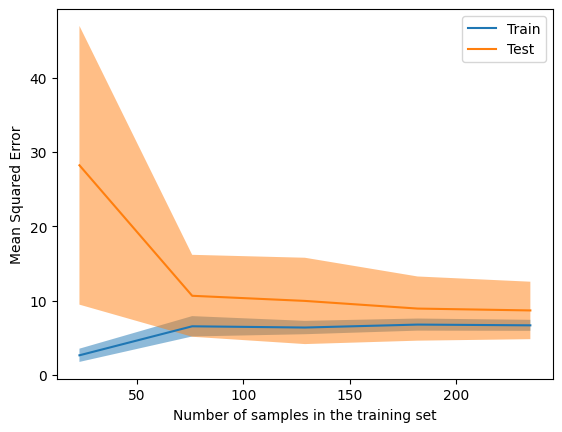

In [37]:
LearningCurveDisplay.from_estimator(
    estimator=tuned_estimator,
    X=X_train,
    y=y_train,
    cv=KFold(shuffle=True, random_state=random_state),
    scoring=scoring,
    random_state=random_state,
    negate_score=True,
    score_name="Mean Squared Error"
)

plt.show()

In [38]:
def model_evaluation(y_true, y_pred, random_state):
    def detect_residual_outlier(target_prediction, target_true):
        residual = target_true - target_prediction
        mean_residual = residual.mean()
        std_residual = residual.std()

        z = (residual - mean_residual) / std_residual
        sigma = 3
        outlier = abs(z) > sigma

        return outlier

    is_outlier = detect_residual_outlier(
        target_true=y_true,
        target_prediction=y_pred
    )

    _, (ax_1, ax_2) = plt.subplots(
        nrows=1,
        ncols=2,
        figsize=(15, 5)
    )

    c = ['orange' if outlier else 'blue' for outlier in is_outlier]
    kwargs = dict(
        y_true=y_true,
        y_pred=y_pred,
        random_state=random_state,
        scatter_kwargs={'c': c}
    )

    PredictionErrorDisplay.from_predictions(
        **kwargs,
        kind='actual_vs_predicted',
        ax=ax_1,
    )

    PredictionErrorDisplay.from_predictions(
        **kwargs,
        kind='residual_vs_predicted',
        ax=ax_2,
    )

    plt.show()

    return is_outlier

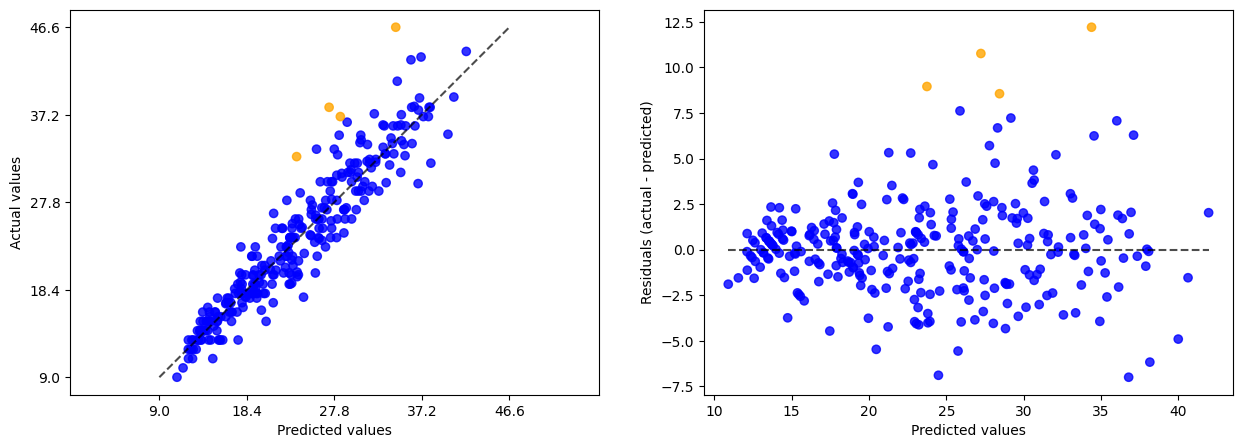

In [39]:
tuned_estimator.fit(
    X=X_train,
    y=y_train
)

y_pred_train = pd.Series(
    data=tuned_estimator.predict(X=X_train),
    index=y_train.index
)

_ = model_evaluation(
    y_true=y_train,
    y_pred=y_pred_train,
    random_state=random_state
)

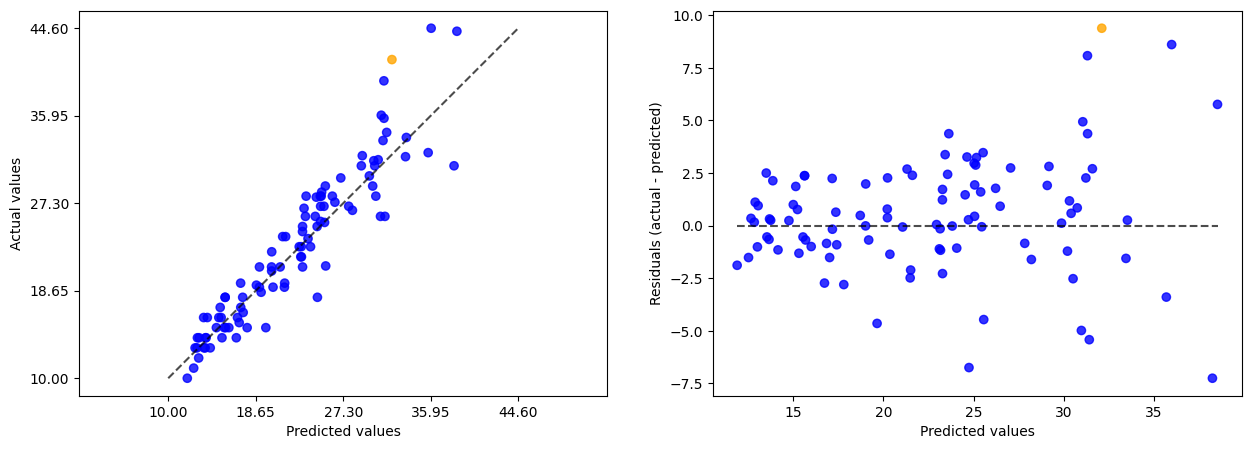

In [40]:
y_pred_test = pd.Series(
    data=tuned_estimator.predict(X=X_test),
    index=y_test.index
)

_ = model_evaluation(
    y_true=y_test,
    y_pred=y_pred_test,
    random_state=random_state
)

In [41]:
pd.DataFrame(
    data=[mean_squared_error(y_true=y_train, y_pred=y_pred_train),
          mean_squared_error(y_true=y_test, y_pred=y_pred_test)],
    index=["train",
           "test"],
    columns=["mse"]
)

,mse
train,6.881320
test,7.885667


                            OLS Regression Results                            
Dep. Variable:                    mpg   R-squared:                       0.896
Model:                            OLS   Adj. R-squared:                  0.884
Method:                 Least Squares   F-statistic:                       nan
Date:                Sat, 14 Feb 2026   Prob (F-statistic):                nan
Time:                        09:22:23   Log-Likelihood:                -689.89
No. Observations:                 294   AIC:                             1440.
Df Residuals:                     264   BIC:                             1550.
Df Model:                          29                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
x1            -0.8701      1.467     -0.593      0.5

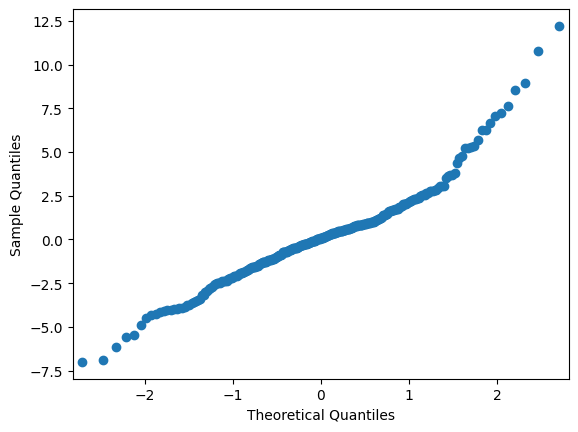

In [42]:
resid_train = y_train - y_pred_train
preprocessor = tuned_estimator.named_steps["preprocessor"]
X_train_transformed = preprocessor.transform(X=X_train)

model = OLS(y_train, X_train_transformed).fit(cov_type='HC3')
print(model.summary())
ax = qqplot(data=resid_train)

In [43]:
resid_train.describe()

count    294.000000
mean       0.130734
std        2.624434
min       -6.996735
25%       -1.338892
50%        0.069830
75%        1.206252
max       12.205443
dtype: float64

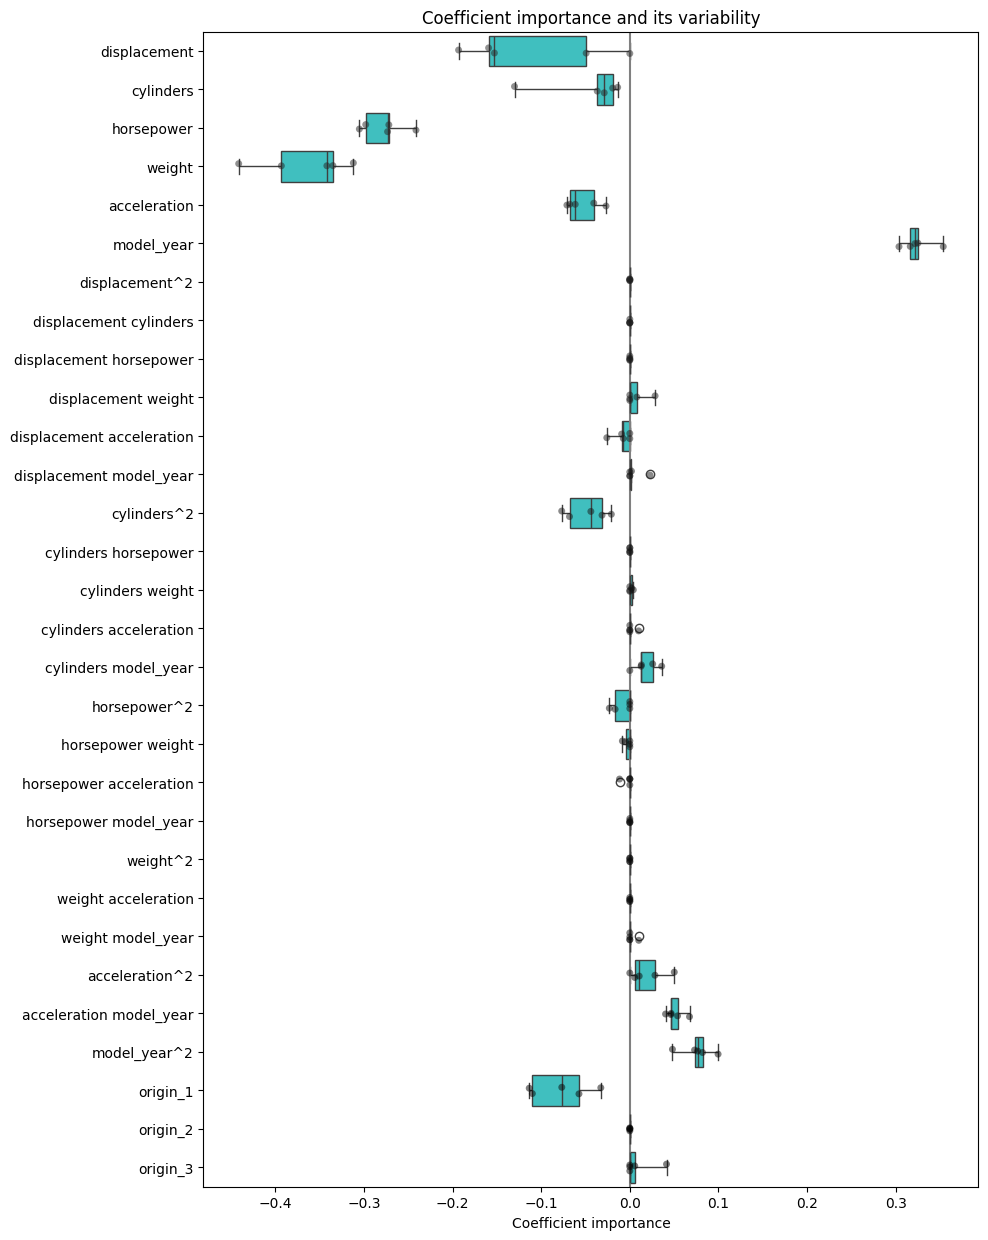

In [44]:
cv_estimator = cross_validate(
    estimator=tuned_estimator,
    X=X_train,
    y=y_train,
    scoring=scoring,
    cv=KFold(shuffle=True, random_state=random_state),
    return_estimator=True
)

feature_names = tuned_estimator['preprocessor'].get_feature_names_out()
coefs = pd.DataFrame(
    data=[estimator['transformedtargetregressor'].regressor_.coef_ for estimator in cv_estimator['estimator']],
    columns=feature_names
)

plt.figure(figsize=(10, 15))
sns.stripplot(data=coefs, orient="h", palette="dark:k", alpha=0.5)
sns.boxplot(data=coefs, orient="h", color="cyan", saturation=0.5, whis=10)
plt.axvline(x=0, color=".5")
plt.xlabel("Coefficient importance")
plt.title("Coefficient importance and its variability")
plt.show()

---

## Reference

* Quinlan, R. (1993). Combining Instance-Based and Model-Based Learning. *In Proceedings on the Tenth International Conference of Machine Learning*, 236-243, University of Massachusetts, Amherst: Morgan Kaufmann.
* Little, R. J. A. (1988). A Test of Missing Completely at Random for Multivariate Data with Missing Values. *Journal of the American Statistical Association, 83*(404), 1198–1202. https://doi.org/10.1080/01621459.1988.10478722
* Tukey, J. W. (1977). *Exploratory Data Analysis*. Reading, Massachusetts: Addison-Wesley.